# Experiment 4: Entropy, Cross-Entropy and KL Divergence

A city observed Sunny, Cloudy and Rainy weather over 30 days. We compare two forecasts against that empirical distribution, verify the cross-entropy identity, demonstrate KL asymmetry and connect log loss with binary classification.

**Tools:** NumPy, SciPy, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Calculate entropy of the observed distribution.  2. Calculate cross-entropy and KL divergence for both forecast models.  3. Verify H(P,Q) = H(P) + DKL(P‖Q).  4. Compare DKL(P‖Q) with DKL(Q‖P).  5. Plot binary cross-entropy for targets 0 and 1.

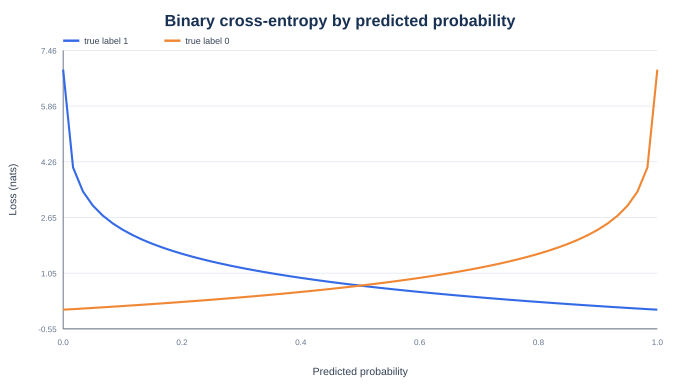

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# A new observed sample for this notebook: 12 Sunny, 11 Cloudy, 7 Rainy days.
counts = np.array([12, 11, 7], dtype=float)
P = counts / counts.sum()
Q_clear = np.array([.42, .36, .22])
Q_uncertain = np.array([.25, .45, .30])
H_P = entropy(P, base=2)

def cross_entropy(p, q):
    return -np.sum(p * np.log2(q))

print("Observed P [Sunny, Cloudy, Rainy]:", np.round(P, 3))
print(f"Entropy H(P): {H_P:.4f} bits")
for name, Q in [("Clear-sky model", Q_clear), ("Uncertain model", Q_uncertain)]:
    ce = cross_entropy(P, Q)
    kl = entropy(P, Q, base=2)
    print(f"\n{name}: Q={Q}")
    print(f"Cross-entropy H(P,Q)={ce:.4f} bits")
    print(f"KL divergence D_KL(P||Q)={kl:.4f} bits")
    print(f"H(P)+D_KL(P||Q)={H_P+kl:.4f} bits; identity verified={np.isclose(ce, H_P+kl)}")

kl_forward = entropy(P, Q_clear, base=2)
kl_reverse = entropy(Q_clear, P, base=2)
print(f"\nAsymmetry check: D_KL(P||Q)={kl_forward:.4f}, D_KL(Q||P)={kl_reverse:.4f}")

eps = 1e-6
prob = np.linspace(eps, 1-eps, 500)
loss_positive = -np.log(prob)
loss_negative = -np.log(1-prob)
plt.figure(figsize=(8, 4.5))
plt.plot(prob, loss_positive, label="True label y=1: −log(p)")
plt.plot(prob, loss_negative, label="True label y=0: −log(1−p)")
plt.xlabel("Predicted probability p"); plt.ylabel("Binary cross-entropy (nats)")
plt.title("Binary cross-entropy penalises confident incorrect predictions")
plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.show()